In [20]:
from pathlib import Path # dosya yolu işlemleri için gerekli kütüphane
import numpy as np
import pandas as pd
import pyreadstat # .sav uzantılı verilerimizi okuması için gerekli kütüphane
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm # istatistiksel modelleme, veri analizi ve hipotez testleri yapmak için kullanılan kütüphane

In [21]:
# Grafik ayarları: tüm grafikler aynı görünsün diye
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True, # eksenler arası çizgiler
    "grid.color": "#e6e6e3",
    "axes.axisbelow": True, # grid çizgileri verilerin arkasında olsun
    "figure.dpi": 110, #çözünürlük
})
MAVI, TURUNCU = "#2a78d6", "#eb6834"

## 1. Veriyi Okuma

In [22]:
VERI_DOSYASI = Path("veriler") / "Data on Cyberbullying Victimization, Depression, Anxiety and Stress" / \
               "Data on Victimisation, Depression, Anxiety & Stress_updated.sav"

df_ham, meta = pyreadstat.read_sav(VERI_DOSYASI)

print("Katılımcı sayısı:", len(df_ham))
print("Yaş etiketleri  :", meta.variable_value_labels["AGE"])

Katılımcı sayısı: 561
Yaş etiketleri  : {1.0: '18 - 19 years old', 2.0: '20-24 years old', 3.0: '>25 years old'}


In [23]:
df_ham.head(10)

,ID,GENDER,AGE,MARITAL_STATUS,EDUCATION_LEVEL,UNIVERSITY_NAME,UNIVERSITY_STATUS,ACTIVE_SOCIAL_MEDIA,TIME_SPENT_SOCIAL_MEDIA,CV1,CV2,CV3,CV4,CV5,CV6,CV7,CV8,CV9,CV10,CV11,CV12,CV13,CV14,CV15,CV16,CV17,CV18,CV19,CV20,CV21,DASS1,DASS2,DASS3,DASS4,DASS5,DASS6,DASS7,DASS8,DASS9,DASS10,DASS11,DASS12,DASS13,DASS14,DASS15,DASS16,DASS17,DASS18,DASS19,DASS20,DASS21,CVTOTAL,CVPUBLICHUMILIATION,CVMALICE,CVUNWANTEDCONTACT,CVDECEPTION,MEANPUBLICHUMILIATION,MEANMALICE,MEANDECEPTION,MEANUNWANTEDCONTACT,SUMSTRESS,SUMANXIETY,SUMDEPRESS,STRESSMULTIPLIED2,DEPRESSMULTIPLIED2,ANXIETYMULTIPLIED2,DEPRESSLEVELS,ANXIETYLEVELS,STRESSLEVELS,PUBLICHUMILIATION_2LEVELS,MALICE_2LEVELS,UNWANTEDCONTACT_2LEVELS,DECEPTION_2LEVELS,PUBLICHUMILIATION_3LEVELS,MALICE_3LEVELS,UNWANTEDCONTACT_3LEVELS,DECEPTION_3LEVELS
0,D1,2.0,1.0,1.0,1.0,4.0,2.0,3.0,2.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,3.0,2.0,2.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,2.0,5.0,8.0,0.0,0.222222,1.0,0.000000,2.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,3.0,3.0,1.0
1,D2,1.0,1.0,1.0,1.0,4.0,2.0,3.0,2.0,2.0,2.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,3.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,2.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,2.0,1.0,1.0,0.0,15.0,6.0,9.0,0.0,0.0,0.666667,1.8,0.000000,0.0,6.0,7.0,3.0,12.0,6.0,14.0,1.0,3.0,1.0,2.0,2.0,1.0,1.0,3.0,3.0,1.0,1.0
2,D3,2.0,1.0,1.0,1.0,4.0,2.0,4.0,3.0,3.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,3.0,3.0,0.0,3.0,4.0,2.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,23.0,9.0,12.0,2.0,0.0,1.000000,2.4,0.000000,0.5,1.0,0.0,2.0,2.0,4.0,0.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,3.0,3.0,2.0,1.0
3,D4,2.0,1.0,1.0,1.0,4.0,2.0,4.0,2.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,2.0,0.0,0.0,0.0,0.222222,0.0,0.000000,0.0,5.0,6.0,4.0,10.0,8.0,12.0,1.0,3.0,1.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0
4,D5,2.0,1.0,1.0,1.0,4.0,2.0,3.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,2.0,1.0,1.0,4.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
5,D6,2.0,1.0,1.0,1.0,4.0,2.0,3.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,1.0,1.0,3.0,2.0,3.0,3.0,2.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,3.0,1.0,1.0,1.0,3.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,14.0,12.0,17.0,28.0,34.0,24.0,5.0,5.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6,D7,2.0,1.0,1.0,1.0,4.0,2.0,3.0,2.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,2.0,2.0,2.0,0.0,2.0,2.0,2.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,22.0,2.0,10.0,6.0,4.0,0.222222,2.0,1.333333,1.5,1.0,0.0,1.0,2.0,2.0,0.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0,3.0
7,D8,2.0,1.0,1.0,1.0,4.0,2.0,4.0,2.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,3.0,0.0,0.0,0.0,0.333333,0.0,0.000000,0.0,3.0,4.0,1.0,6.0,2.0,8.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0
8,D9,2.0,1.0,1.0,2.0,4.0,2.0,2.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,7.0,3.0,7.0,14.0,14.0,6.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
9,D10,1.0,1.0,1.0,2.0,4.0,2.0,3.0,5.0,2.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,0.0,3.0,0.0,3.0,3.0,0.0,0.0,0.0,0.0,0.0,3.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,6.0,9.0,0.0,5.0,0.666667,1.8,1.666667,0.0,1.0,0.0,0.0,2.0,0.0,0.0,1.0,1.0,1.0,2.0,2.0,1.0,2.0,3.0,3.0,1.0,3.0


## 2. Veri Kalitesi Kontrolü

Her ölçeğin izin verilen bir aralığı var. Bu yüzden DASS maddeleri **0–3**, CV maddeleri **0–5**. Bu aralığın dışındaki bir değer (örneğin 13 gibi) giriş hatalıdır ve toplam puanı da bozduğundan bu satırları ayıklamamız gerekir.

In [24]:
cv_sutunlari   = [f"CV{i}" for i in range(1, 22)]     # CV1, CV2, ... CV21
dass_sutunlari = [f"DASS{i}" for i in range(1, 22)]   # DASS1, ... DASS21

# Her satır için aralık dışında en az bir değer var mı (True / False)
cv_hatali   = (df_ham[cv_sutunlari] > 5).any(axis=1)
dass_hatali = (df_ham[dass_sutunlari] > 3).any(axis=1)
hatali_satir = cv_hatali | dass_hatali     # ikisinden biri hatalıysa

print("Hatalı CV değeri olan satır  :", cv_hatali.sum())
print("Hatalı DASS değeri olan satır:", dass_hatali.sum())
print(f"Toplam çıkarılacak satır     : {hatali_satir.sum()} (%{hatali_satir.mean() * 100:.1f})")

Hatalı CV değeri olan satır  : 7
Hatalı DASS değeri olan satır: 15
Toplam çıkarılacak satır     : 22 (%3.9)


#### **ANALİZ** 
- **22 satırda (%3,9) ölçek dışı değer** var. örneğin bir katılımcı **0–3** arası olması gereken bir maddeye farklı bir değer yazamaz. Bundan dolayı bu satırları çıkardık. 

### 2.1. Aynı ID'yi taşıyan satırlar var mı?

In [25]:
ayni_id = df_ham[df_ham["ID"].duplicated(keep=False)] # Tüm tekrarlı satırları (ilk örnekler dahil) getirme
print(ayni_id[["ID", "GENDER", "AGE", "UNIVERSITY_STATUS"]])

print("Sosyal medya süresinde eksik değer:", df_ham["TIME_SPENT_SOCIAL_MEDIA"].isna().sum())


       ID  GENDER  AGE  UNIVERSITY_STATUS
150  D152     1.0  3.0                2.0
151  D152     1.0  2.0                1.0
499  D500     2.0  2.0                1.0
508  D500     1.0  2.0                1.0
Sosyal medya süresinde eksik değer: 4


#### **ANALİZ**
- **D152 ve D500** numaraları iki farklı kişide kullanılmış (demografileri farklı). Bunlar kopya değil, ID çakışması; ikisini de tuttuk.
- Sosyal medya süresinde **4 eksik değer** var. Bu değişkeni ana analizde kullanmıyoruz.

In [26]:
# Hatalı satırları çıkarıyoruz (~ işareti 'değil' anlamına gelir)
df = df_ham[~hatali_satir].copy()
print("Analize giren katılımcı:", len(df))

Analize giren katılımcı: 539


## 3. Değişkenleri Hazırlama

Sayısal kodları anlaşılır etiketlere çevirdik. Her psikolojik durum için bir de **"orta ve üzeri" (1 = evet, 0 = hayır)** sütunu oluşturduk.

In [27]:
df["Cinsiyet"]   = df["GENDER"].map({1: "Erkek", 2: "Kadın"})
df["Yaş"]        = df["AGE"].map({1: "18-19", 2: "20-24", 3: "25+"})
df["Üniversite"] = df["UNIVERSITY_STATUS"].map({1: "Kamu", 2: "Özel"})

seviye = {1: "Normal", 2: "Hafif", 3: "Orta", 4: "Şiddetli", 5: "Çok şiddetli"}
durumlar = {"Depresyon": "DEPRESSLEVELS", "Anksiyete": "ANXIETYLEVELS", "Stres": "STRESSLEVELS"}

for ad, sutun in durumlar.items():
    df[ad] = df[sutun].map(seviye)
    df[ad + "_orta_ustu"] = (df[sutun] >= 3).astype(int)   # 3 = orta, 4 = şiddetli, 5 = çok şiddetli

**İstenmeyen cinsel içerik değişkeni:** CV15, CV16 ve CV17 maddeleri cinsel içerikli. Bu maddeler bir **sıklık ölçeği** olduğu için "en az birinde 0'dan büyük değer" = "en az bir kez yaşadı" demek. CV18 yalnızca rahatsız edici görsel sorduğu için dahil edilmedi.

In [28]:
cv = [f"CV{i}" for i in range(1, 22)]

for m in cv:
    print(m, "→", meta.column_names_to_labels[m])

CV1 → Has someone distributed information electronically while pretending to be you?
CV2 → Has someone changed a picture of you in a negative way and posted it electronically?
CV3 → Has someone written mean messages about you publicly electronically?
CV4 → Has someone logged into your electronic account and changed your information?
CV5 → Has someone posted a nude picture of you electronically?
CV6 → Has someone printed out an electronic conversation you had and then showed it to others?
CV7 → Have you completed an electronic survey that was supposed to remain private but the answers were sent to someone else?
CV8 → Has someone logged into your electronic account and pretended to be you?
CV9 → Has someone posted an embarrassing picture of you electronically where other people could see it?
CV10 → Has someone called you mean names electronically?
CV11 → Has someone been mean to you electronically?
CV12 → Has someone cursed at you electronically?
CV13 → Has someone made fun of you electr

In [29]:
for madde in ["CV15", "CV16", "CV17", "CV18"]:
    print(madde, "→", meta.column_names_to_labels[madde])

df["Cinsel_taciz"] = (df[["CV15", "CV16", "CV17"]] > 0).any(axis=1).astype(int)

CV15 → Have you received a nude or partially nude picture that you did not want from someone you were talking to electronically?
CV16 → Have you received a pornographic picture that you did not want from someone electronically that was not spam?
CV17 → Have you received an unwanted sexual message from someone electronically?
CV18 → Have you received an offensive picture electronically that was not spam?


## 4. Tanımlayıcı İstatistikler

In [30]:
for ad in durumlar:
    yuzde = df[ad + "_orta_ustu"].mean() * 100
    print(f"{ad:10s} → orta ve üzeri: %{yuzde:.1f}")

print(f"\nEn az bir kez siber mağduriyet yaşayan (CVTOTAL > 0): %{(df['CVTOTAL'] > 0).mean() * 100:.1f}")
print(f"İstenmeyen cinsel içeriği en az bir kez yaşayan     : %{df['Cinsel_taciz'].mean() * 100:.1f}")

for sutun in ["Cinsiyet", "Yaş", "Üniversite"]:
    print()
    print(df[sutun].value_counts().to_string())

Depresyon  → orta ve üzeri: %30.1
Anksiyete  → orta ve üzeri: %44.0
Stres      → orta ve üzeri: %16.9

En az bir kez siber mağduriyet yaşayan (CVTOTAL > 0): %72.4
İstenmeyen cinsel içeriği en az bir kez yaşayan     : %34.1

Cinsiyet
Kadın    305
Erkek    234

Yaş
20-24    388
25+       90
18-19     61

Üniversite
Kamu    388
Özel    151


### Grafik 1 : Şiddet düzeylerinin dağılımı

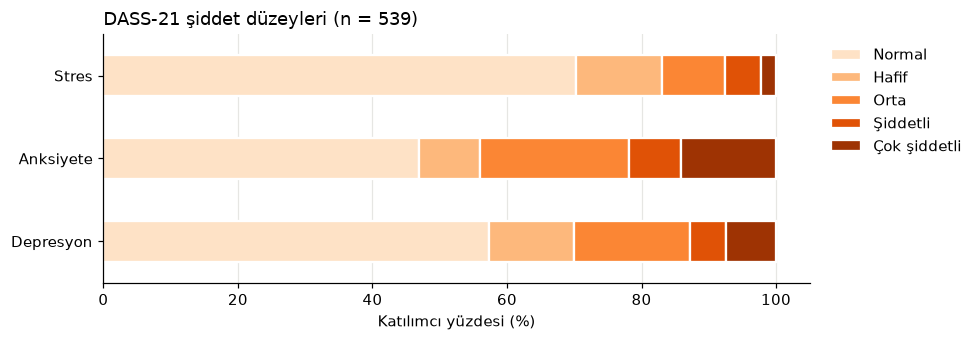

In [31]:
yuzdeler = pd.DataFrame({
    ad: df[ad].value_counts(normalize=True).reindex(list(seviye.values())).fillna(0) * 100
    for ad in durumlar
}).T

renkler = plt.cm.Oranges(np.linspace(0.15, 0.9, 5))   # açık renk: Normal → koyu renk: Çok şiddetli
ax = yuzdeler.plot(kind="barh", stacked=True, figsize=(9, 3.2), color=renkler,
                   edgecolor="white", linewidth=1.5)
ax.set_xlabel("Katılımcı yüzdesi (%)")
ax.set_ylabel("")
ax.set_title(f"DASS-21 şiddet düzeyleri (n = {len(df)})", loc="left")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Grafik 2 : Yaş grubu ve cinsiyete göre orta+ depresyon oranı

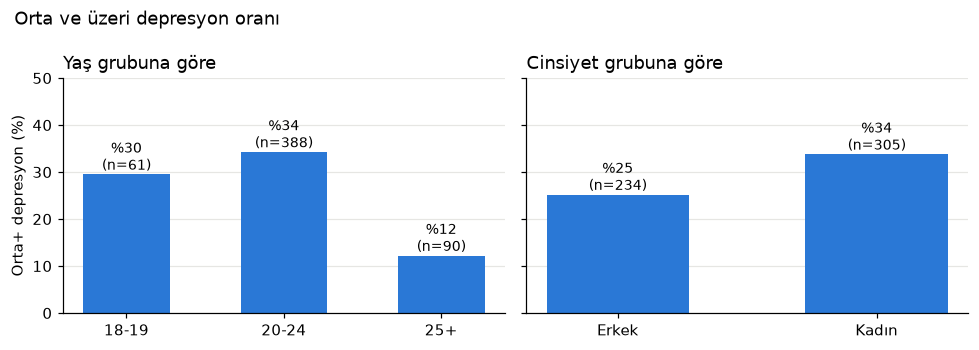

In [32]:
fig, eksenler = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)

for ax, grup in zip(eksenler, ["Yaş", "Cinsiyet"]):
    oran = df.groupby(grup)["Depresyon_orta_ustu"].mean() * 100
    sayi = df[grup].value_counts()
    ax.bar(oran.index, oran.values, color=MAVI, width=0.55)
    for x, y in zip(oran.index, oran.values):
        ax.text(x, y + 1, f"%{y:.0f}\n(n={sayi[x]})", ha="center", fontsize=9)
    ax.set_title(f"{grup} grubuna göre", loc="left")
    ax.set_ylim(0, 50)
    ax.grid(axis="x", visible=False)

eksenler[0].set_ylabel("Orta+ depresyon (%)")
fig.suptitle("Orta ve üzeri depresyon oranı", x=0.02, ha="left")
plt.tight_layout()
plt.show()

#### **ANALİZ**

- Veride bulunan 539 öğrencide orta ve üzeri belirti oranlarına bakarak **depresyon %30,1**, **anksiyete %44,0**, **stres %16,9** olarak görülmüş. Siber zorbalığa uğrayan kişilerde anksiyete en yaygın sorun olarak görüldüğü söylenebilir.
- Öğrencilerin **%72,4'ü** en az bir kez siber mağduriyet yaşamış; **%34,1'i** istenmeyen cinsel içerikle karşılaşmış.
- **25 yaş üstü** grupta orta ve üstü depresyon oranı diğer yaş gruplarından belirgin şekilde düşük. **Kadınlarda** oran erkeklerden yüksek. (Bu farkların istatistiksel olarak anlamlı olup olmadığını Bölüm 5.3'te test edilecektir.)

## 5. İlişki Analizleri

### 5.1 Mağduriyet puanı ile DASS puanları: Spearman korelasyonu

Spearman korelasyon analizi, iki değişken arasındaki ilişkinin yönünü ve gücünü, verilerin ham sayısal değerleri yerine sıra (rank) değerlerini kullanarak ölçen parametrik olmayan bir istatistiksel yöntemdir.

Spearman korelasyonu iki değişkenin **birlikte artıp azalma** eğilimini ölçer (-1 ile +1 arası). Kabaca: 0,3'ün altı **zayıf**, 0,3–0,5 **orta**, 0,5'in üstü **güçlü** ilişki.

In [33]:
for ad, sutun in [("Depresyon", "SUMDEPRESS"), ("Anksiyete", "SUMANXIETY"), ("Stres", "SUMSTRESS")]:
    rho, p = stats.spearmanr(df["CVTOTAL"], df[sutun])
    print(f"{ad:10s} → rho = {rho:.2f}   p = {p:.4f}")

Depresyon  → rho = 0.13   p = 0.0020
Anksiyete  → rho = 0.16   p = 0.0003
Stres      → rho = 0.17   p = 0.0001


#### **ANALİZ**
- Üç belirtide de korelasyon pozitif ve istatistiksel olarak anlamlı (p < 0,05), ama **zayıf** (rho = 0,13–0,17 arasında).

Yani mağduriyet puanı yüksek olanlarda belirtiler biraz daha yüksek olma eğiliminde ancak mağduriyet puanı, belirtilerdeki farklılığın çok küçük bir kısmıyla ilişkili.

### 5.2 İstenmeyen cinsel içerik ile belirtiler: Ki-kare testi

Ki-kare testi iki kategorik değişkenin (burada: "cinsel içerik yaşadı mı?" ve "orta+ belirti var mı?") birbirinden bağımsız olup olmadığını test ediyor.

In [34]:
for ad in durumlar:
    hedef = ad + "_orta_ustu"
    tablo = pd.crosstab(df["Cinsel_taciz"], df[hedef])
    chi2, p, _, _ = stats.chi2_contingency(tablo)

    yasamayan = df.loc[df["Cinsel_taciz"] == 0, hedef].mean() * 100
    yasayan   = df.loc[df["Cinsel_taciz"] == 1, hedef].mean() * 100
    print(f"{ad:10s} → yaşamayan: %{yasamayan:.1f} | yaşayan: %{yasayan:.1f} | p = {p:.3f}")

Depresyon  → yaşamayan: %28.2 | yaşayan: %33.7 | p = 0.219
Anksiyete  → yaşamayan: %41.7 | yaşayan: %48.4 | p = 0.165
Stres      → yaşamayan: %14.4 | yaşayan: %21.7 | p = 0.041


#### **ANALİZ**
- İstenmeyen cinsel içerik yaşayanlarda üç belirtinin oranı yüksek fakat fark yalnızca **stres** için istatistiksel olarak anlamlı (%14,4'e karşı %21,7; p = 0,041). Depresyon ve anksiyetedeki farklar şans eseri de oluşmuş olabilir.

### 5.3 Lojistik Regresyon: Orta ve üstü depresyonla birlikte görülen faktörler

- Lojistik regresyon, **birden fazla değişkeni aynı anda** hesaba katarak bir evet/hayır sonucunu (orta+ depresyon var mı?) açıklamaya çalışır. Böylece örneğin cinsiyetin etkisine bakarken yaş farkını sabit tutmuş oluruz.

**Odds nedir?**
- Odds, olasılığın başka bir ifade şeklidir:

        odds = olma olasılığı / olmama olasılığı

**Odds oranı (OR) nedir?**

- İki grubun odds’unun birbirine oranıdır.

In [35]:
# Açıklayıcı değişkenler (hepsi 0/1, mağduriyet hariç)
X = pd.DataFrame({
    "Kadın":            (df["GENDER"] == 2).astype(int),
    "25 yaş üstü":      (df["AGE"] == 3).astype(int),
    "Özel üniversite":  (df["UNIVERSITY_STATUS"] == 2).astype(int),
    "Mağduriyet (log)": np.log1p(df["CVTOTAL"]),   # log(1 + puan): çok yüksek puanların etkisini yumuşatır
})
X = sm.add_constant(X) # modele sabit terim (başlangıç noktası) ekler
y = df["Depresyon_orta_ustu"]

model = sm.Logit(y, X).fit(disp=0)

# Katsayılar log-odds cinsinden çıkar; np.exp() ile odds oranına çeviriyoruz
sonuc = pd.DataFrame({
    "OR":     np.exp(model.params),
    "CI_alt": np.exp(model.conf_int()[0]),
    "CI_ust": np.exp(model.conf_int()[1]),
    "p":      model.pvalues,
}).drop("const").round(3)

print(sonuc)

                     OR  CI_alt  CI_ust      p
Kadın             1.539   1.041   2.276  0.030
25 yaş üstü       0.289   0.147   0.568  0.000
Özel üniversite   0.765   0.499   1.174  0.220
Mağduriyet (log)  1.110   0.957   1.288  0.167


### Grafik 3 : Odds oranları ve %95 güven aralıkları

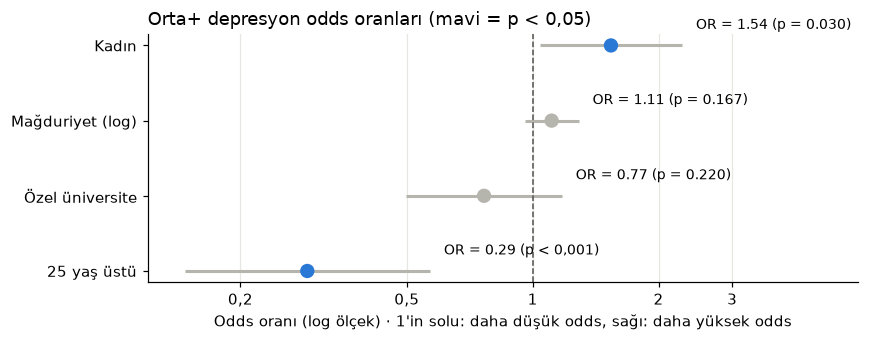

In [36]:
tablo = sonuc.sort_values("OR")
konum = np.arange(len(tablo))
anlamli = tablo["p"] < 0.05

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hlines(konum, tablo["CI_alt"], tablo["CI_ust"], color="#b5b4ad", linewidth=2)   # güven aralığı çizgisi
ax.scatter(tablo["OR"], konum, s=70, zorder=3,
           color=[MAVI if a else "#b5b4ad" for a in anlamli])                     # OR noktası
ax.axvline(1, color="#52514e", linestyle="--", linewidth=1)                        # OR = 1 çizgisi

for i in range(len(tablo)):
    p = tablo["p"].iloc[i]
    p_yazi = "p < 0,001" if p < 0.001 else f"p = {p:.3f}"
    ax.text(tablo["CI_ust"].iloc[i] * 1.08, i + 0.22, f"OR = {tablo['OR'].iloc[i]:.2f} ({p_yazi})", fontsize=9)

ax.set_yticks(konum, tablo.index)
ax.set_xscale("log")
ax.set_xticks([0.2, 0.5, 1, 2, 3], ["0,2", "0,5", "1", "2", "3"])
ax.set_xticks([], minor=True)
ax.set_xlim(0.12, 6)
ax.set_xlabel("Odds oranı (log ölçek) · 1'in solu: daha düşük odds, sağı: daha yüksek odds")
ax.set_title("Orta+ depresyon odds oranları (mavi = p < 0,05)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

#### **ANALİZ**
- Dikey Kesikli Çizgi (OR = 1): Etkisizlik çizgisidir. Bir değişkenin nokta tahmini ve güven aralığı (yatay çizgiler) bu kesikli çizgiyi kesiyorsa, o değişkenin depresyon üzerinde istatistiksel olarak anlamlı bir etkisi yoktur.

- Çizginin Sağ Tarafı (OR > 1): İlgili faktörün, orta ve üstü depresyon görülme olasılığını artırdığını gösterir.

- Çizginin Sol Tarafı (OR < 1): İlgili faktörün, orta ve üstü depresyon görülme olasılığını azalttığını (koruyucu etki) gösterir.

- Mavi Noktalar : İstatistiksel olarak anlamlı 
- Gri Noktalar : İstatistiksel olarak anlamsız

Bu bilgilere dayanarak:
    - Kadın ve 25 yaş üstü veriler istatistiksel olarak anlamlıdır. 
    - Kadın OR değeri 1'den büyük bu da kadın olmanın orta ve üstü düzeyde depresyon riskinin fazla olduğunu göstermektedir.
    - 25 yaş üstü OR değeri 1'den küçük bu da 25 yaşından büyük olmanın orta ve üstü düzeyde depresyon görülme olasılığını azalttığını gösterir.


## 6. Genel Sonuç

- Öğrencilerin yaklaşık üçte birinde orta ve üstü depresyon, yarıya yakınında orta ve üstü anksiyete var. 
- Mağduriyet ile üç belirti arasında zayıf pozitif ilişki var. 
-  İstenmeyen cinsel içerik yaşayanlarda orta ve üstü stres daha sık görülmüş. 
- 25 yaş üstünde orta ve üstü depresyon odds'u daha düşük görülmüş
- Kadınlarda orta ve üstü depresyon odds'u daha yüksek görülmüş
- Diğer değişkenler sabitken mağduriyetle orta+ depresyon arasında anlamlı ilişki bulunamadı.

**Sınırlılıklar:**
- Kesitsel veri: ilişki gösterir, neden-sonuç göstermez.
- Tek ülke, yalnızca üniversite öğrencileri; sonuçlar başka gruplara genellenemez.

# Ek: İleri Analizler
Bu bölüm ana sonucu desteklemek amacı taşır.

### Ek A: Modelin açıklama gücü
- **McFadden R²:** Modelin, hiçbir değişken içermeyen boş bir modele göre ne kadar iyileştiğini gösterir. 0,2–0,4 arası iyi kabul edilir.
- **AUC:** Model, rastgele seçilen bir "orta+ depresyon var" kişiye, "yok" kişiden daha yüksek olasılık verebiliyor mu?

In [37]:
from sklearn.metrics import roc_auc_score

tahmin_olasilik = model.predict(X)
print(f"McFadden R²                 = {model.prsquared:.3f}")
print(f"AUC (eğitim verisi üzerinde) = {roc_auc_score(y, tahmin_olasilik):.3f}")

McFadden R²                 = 0.040
AUC (eğitim verisi üzerinde) = 0.632


#### **ANALİZ**
- Modelin açıklama gücü düşük (R² = 0,04). Yaş, cinsiyet, üniversite türü ve mağduriyet birlikte, orta ve üstü depresyonu açıklamakta çok sınırlı kalıyor. Depresyonla ilişkili başka önemli faktörler (aile, ekonomik durum, akademik baskı vb.) bu veride olmadığından dolayı tam kesin bir kanıya varılamamaktadır.

### Ek B: Hatalı satırlar temizlenmeseydi?

In [39]:
df_ham["Depresyon_orta_ustu"] = (df_ham["DEPRESSLEVELS"] >= 3).astype(int)
X_ham = pd.DataFrame({
    "Kadın":            (df_ham["GENDER"] == 2).astype(int),
    "25 yaş üstü":      (df_ham["AGE"] == 3).astype(int),
    "Özel üniversite":  (df_ham["UNIVERSITY_STATUS"] == 2).astype(int),
    "Mağduriyet (log)": np.log1p(df_ham["CVTOTAL"]),
})
model_ham = sm.Logit(df_ham["Depresyon_orta_ustu"], sm.add_constant(X_ham)).fit(disp=0)

karsilastirma = pd.DataFrame({
    "OR (temizlenmemiş)": np.exp(model_ham.params),
    "p (temizlenmemiş)":  model_ham.pvalues,
    "OR (temizlenmiş)":   np.exp(model.params),
    "p (temizlenmiş)":    model.pvalues,
}).drop("const").round(3)
print(karsilastirma)
print(f"Orta+ depresyon oranı: temizlenmemiş %{df_ham['Depresyon_orta_ustu'].mean()*100:.1f} → temizlenmiş %{y.mean()*100:.1f}")

                  OR (temizlenmemiş)  p (temizlenmemiş)  OR (temizlenmiş)  \
Kadın                          1.739              0.004             1.539   
25 yaş üstü                    0.292              0.000             0.289   
Özel üniversite                0.681              0.075             0.765   
Mağduriyet (log)               1.148              0.063             1.110   

                  p (temizlenmiş)  
Kadın                       0.030  
25 yaş üstü                 0.000  
Özel üniversite             0.220  
Mağduriyet (log)            0.167  
Orta+ depresyon oranı: temizlenmemiş %31.7 → temizlenmiş %30.1


#### **ANALİZ**

- Sadece 22 satırı çıkarmak sonuçları fark edilir biçimde değiştirdi. Orta ve üstü depresyon oranı %31,7'den %30,1'e, kadınların odds oranı 1,74'ten 1,54'e indi mağduriyetin p değeri 0,063'ten 0,167'ye çıktı. Veri temizliği, sonuçların güvenilirliği için kritik bir nokta.